# 2 Data Understanding and Background #
Report sections 2.2 *Dataset Description*, 2.3 *Exploratory Data Analysis* and 2.4 *Data Quality Issues*.

| Report | Output |
|---|---|
| Table `tab:dataset_locations` | `results/tables/dataset_locations.tex` |
| Figure `fig:consumption-level` | `results/figures/consumption_level.png` |
| Figure `fig:temp-scatter` | `results/figures/temperature_scatter.png` |
| Figure `fig:daily-profiles` | `results/figures/daily_profiles.png` |

**Inputs:** `data/consumption_temp.csv` (given) and `data/weather_2022_2024.csv` (from `fetch_weather_data.py`). **Run time:** under a minute.

In [1]:
from pathlib import Path

DATA_DIR = Path("../data")
CONSUMPTION_DATA = DATA_DIR / "consumption_temp.csv"
WEATHER_DATA = DATA_DIR / "weather_2022_2024.csv"
FIGURES, TABLES = Path("results/figures"), Path("results/tables")
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

In [3]:
#Shared plot style: recessive axes and grid, fixed colours
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.5,
    "xtick.color": "#898781",
    "ytick.color": "#898781",
})
#Locations in report order, their names and price areas, and a fixed colour per location
ORDER = ["oslo", "stavanger", "trondheim", "tromsø", "bergen", "helsingfors"]
NAMES = {"oslo": "Oslo", "stavanger": "Stavanger", "trondheim": "Trondheim",
         "tromsø": "Tromsø", "bergen": "Bergen", "helsingfors": "Helsingfors"}
PRICE_AREAS = {"oslo": "NO1", "stavanger": "NO2", "trondheim": "NO3", "tromsø": "NO4", "bergen": "NO5",
               "helsingfors": "FI"}
COLORS = {"oslo": "#2a78d6", "stavanger": "#eb6834", "trondheim": "#1baf7a",
          "helsingfors": "#008300", "bergen": "#e87ba4", "tromsø": "#6250d6"}
TIMEZONES = {"helsingfors": "Europe/Helsinki"}   #every other location is in Europe/Oslo

In [4]:
#Load both files with time as UTC so they can be joined on (time, location)
consumption = pd.read_csv(CONSUMPTION_DATA)
consumption["time"] = pd.to_datetime(consumption["time"], utc=True)

weather = pd.read_csv(WEATHER_DATA)
weather["time"] = pd.to_datetime(weather["time"], utc=True)

In [5]:
class DatasetExplorer:
    """Runs the same exploration checks on any hourly dataset with `time` and `location` columns."""

    def __init__(self, name, df):
        self.name = name
        self.df = df
        self.numeric_cols = df.select_dtypes("number").columns

    def missing_values(self):
        """NaN count and share for every column."""
        return pd.DataFrame({"missing": self.df.isna().sum(),
                             "missing_pct": self.df.isna().mean() * 100})

    def missing_hours(self):
        """Per location: hours absent from an uninterrupted hourly range, and duplicated timestamps."""
        rows = {}
        for location, group in self.df.groupby("location"):
            expected = pd.date_range(group["time"].min(), group["time"].max(), freq="h")
            rows[location] = {"start": group["time"].min(),
                              "end": group["time"].max(),
                              "rows": len(group),
                              "missing_hours": len(expected.difference(group["time"])),
                              "duplicate_hours": group["time"].duplicated().sum()}
        return pd.DataFrame.from_dict(rows, orient="index")

    def summary(self):
        """Descriptive statistics per location for every numeric column."""
        return self.df.groupby("location")[self.numeric_cols].describe().T

    def plot_distributions(self, ncols=3):
        """One boxplot panel per numeric column, locations side by side."""
        nrows = int(np.ceil(len(self.numeric_cols) / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows), squeeze=False)
        locations = sorted(self.df["location"].unique())
        for ax, col in zip(axes.flat, self.numeric_cols):
            groups = [self.df.loc[self.df["location"] == loc, col].dropna() for loc in locations]
            ax.boxplot(groups, tick_labels=locations, medianprops={"color": BLUE, "linewidth": 2},
                       flierprops={"markersize": 2, "alpha": 0.3})
            ax.set_title(col)
            ax.tick_params(axis="x", rotation=45)
        for ax in axes.flat[len(self.numeric_cols):]:
            ax.set_visible(False)
        fig.suptitle(f"{self.name}: distribution per location")
        fig.tight_layout()
        plt.show()

## Missing values and gaps (2.2 Dataset Description, 2.4 Data Quality Issues) ##

In [6]:
#Missing values
#for every column of both data files, check for missing data
for explorer in [DatasetExplorer("consumption", consumption), DatasetExplorer("weather", weather)]:
    print(f"--- {explorer.name}: missing values per column ---")
    display(explorer.missing_values())
    print(f"--- {explorer.name}: gaps in the hourly series ---")
    display(explorer.missing_hours())

#Zero consumption is not a NaN, but means the hour was not delivered
print("--- consumption: hours reported as 0 MW ---")
display(consumption[consumption["consumption"] <= 0].groupby("location")["time"].agg(["min", "max", "count"]))

--- consumption: missing values per column ---


,missing,missing_pct
time,0,0.0
location,0,0.0
consumption,0,0.0
temperature,0,0.0


--- consumption: gaps in the hourly series ---


,start,end,rows,missing_hours,duplicate_hours
bergen,2022-04-07 21:00:00+00:00,2023-04-02 21:00:00+00:00,8641,0,0
helsingfors,2022-07-14 21:00:00+00:00,2023-04-02 21:00:00+00:00,6289,0,0
oslo,2022-04-07 21:00:00+00:00,2023-04-02 21:00:00+00:00,8641,0,0
stavanger,2022-04-07 21:00:00+00:00,2023-04-02 21:00:00+00:00,8641,0,0
tromsø,2022-04-07 21:00:00+00:00,2023-04-02 21:00:00+00:00,8641,0,0
trondheim,2022-04-07 21:00:00+00:00,2023-04-02 21:00:00+00:00,8641,0,0


--- weather: missing values per column ---


,missing,missing_pct
time,0,0.0
location,0,0.0
temperature_2m,0,0.0
precipitation,0,0.0
rain,0,0.0
snowfall,0,0.0
wind_speed_10m,0,0.0
wind_gusts_10m,0,0.0
wind_direction_10m,0,0.0


--- weather: gaps in the hourly series ---


,start,end,rows,missing_hours,duplicate_hours
bergen,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,26304,0,0
helsingfors,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,26304,0,0
oslo,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,26304,0,0
stavanger,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,26304,0,0
tromsø,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,26304,0,0
trondheim,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,26304,0,0


--- consumption: hours reported as 0 MW ---


,min,max,count
location,,,
helsingfors,2022-07-14 21:00:00+00:00,2022-07-16 04:00:00+00:00,32


In [7]:
#Table tab:dataset_locations: observations per location
counts = DatasetExplorer("consumption", consumption).missing_hours()["rows"]
locations = pd.DataFrame({"Location": [NAMES[loc] for loc in ORDER],
                          "Price area": [PRICE_AREAS[loc] for loc in ORDER],
                          "Observations": [counts[loc] for loc in ORDER]})
locations.loc[len(locations)] = ["Total", "", counts.sum()]
(TABLES / "dataset_locations.tex").write_text(locations.to_latex(index=False, formatters={"Observations": "{:,}".format}))
locations

,Location,Price area,Observations
0,Oslo,NO1,8641
1,Stavanger,NO2,8641
2,Trondheim,NO3,8641
3,Tromsø,NO4,8641
4,Bergen,NO5,8641
5,Helsingfors,FI,6289
6,Total,,49494


No NaNs, gaps or duplicate hours in either file. Helsingfors reports 0 MW for its first 32 hours: those hours were not delivered, so they are treated as missing below.

In [8]:
#Treat 0 MW hours as missing so they do not distort the distributions and figures below
consumption["consumption"] = consumption["consumption"].mask(consumption["consumption"] <= 0)

In [9]:
#Join weather onto consumption so every variable covers the same hours
merged = consumption.merge(weather, on=["time", "location"], how="left")
unmatched = merged[weather.columns.drop(["time", "location"])].isna().any(axis=1).sum()
print(f"{len(merged)} rows, {unmatched} without a weather match")

49494 rows, 0 without a weather match


location                       bergen  helsingfors         oslo    stavanger  \
consumption        count  8641.000000  6257.000000  8641.000000  8641.000000   
                   mean      1.876716     6.108322     6.876428     3.304703   
                   std       1.156034     0.812314     4.672634     2.112962   
                   min       0.443192     0.339000     1.520560     0.832372   
                   25%       0.834003     6.194000     2.610569     1.382764   
...                               ...          ...          ...          ...   
wind_direction_10m min       1.000000     1.000000     1.000000     1.000000   
                   25%     124.000000   120.000000    57.000000   135.000000   
                   50%     163.000000   212.000000   172.000000   182.000000   
                   75%     268.000000   267.000000   220.000000   304.000000   
                   max     360.000000   360.000000   360.000000   360.000000   

location                       tromsø    trondheim  
consumption        count  8641.000000  8641.000000  
                   mean      1.340776     2.278574  
                   std       0.559151     1.137311  
                   min       0.372637     0.620001  
                   25%       0.831883     1.263027  
...                               ...          ...  
wind_direction_10m min       2.000000     2.000000  
                   25%     143.000000    97.000000  
                   50%     178.000000   194.000000  
                   75%     221.000000   264.000000  
                   max     360.000000   360.000000  

[72 rows x 6 columns]

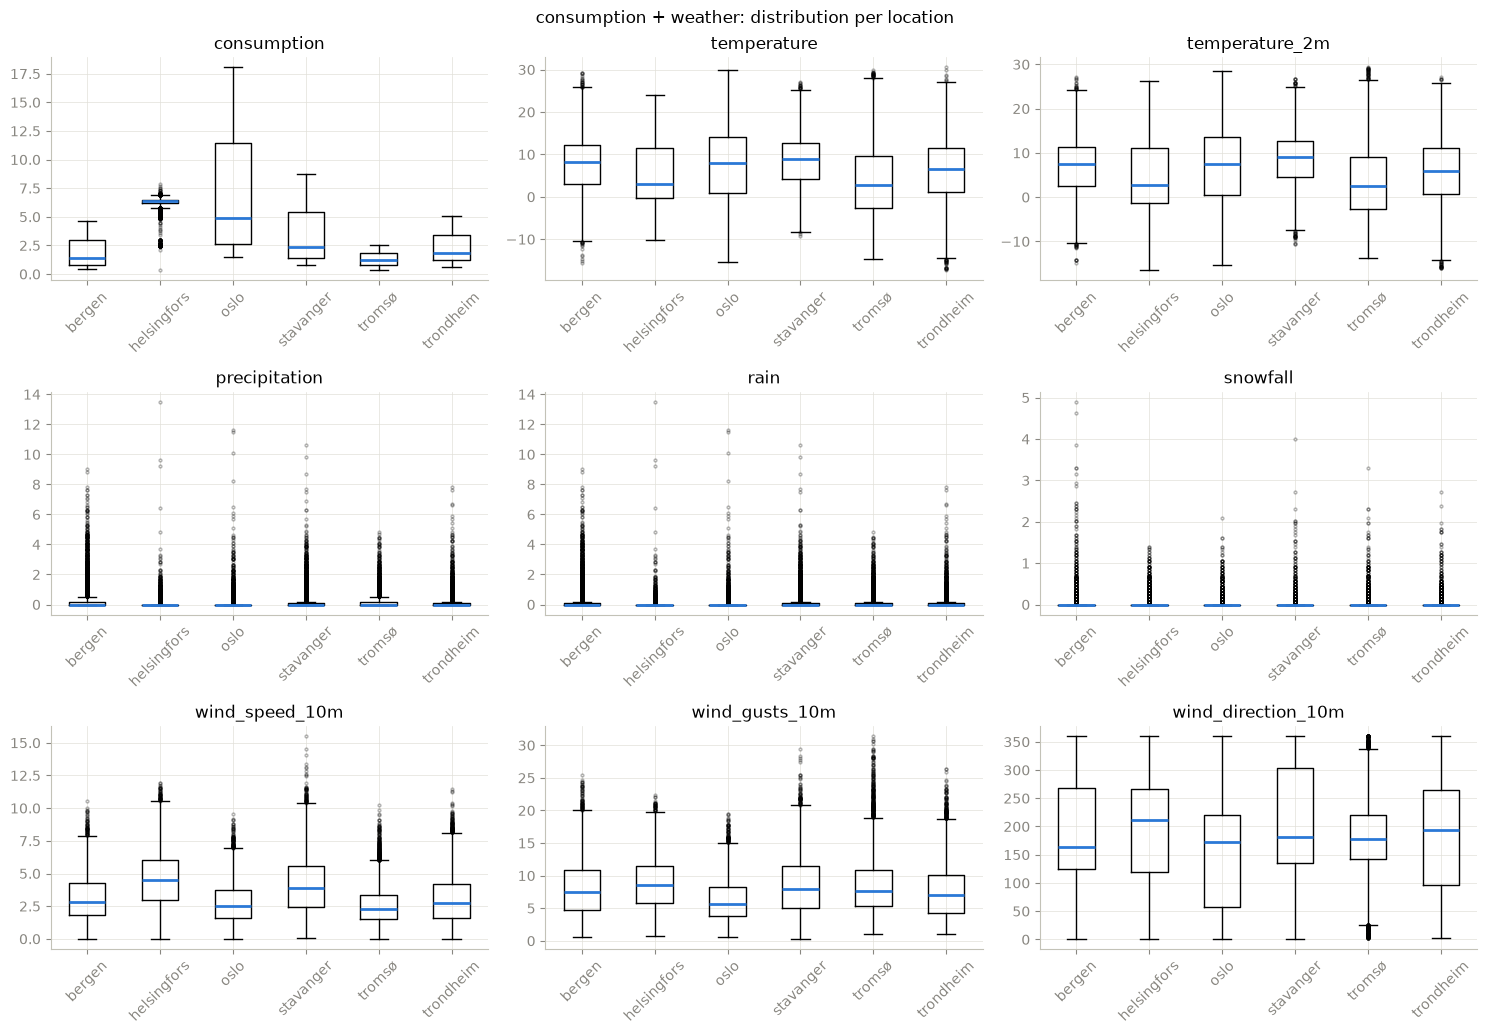

In [10]:
#distribution of values
merged_explorer = DatasetExplorer("consumption + weather", merged)
display(merged_explorer.summary())
merged_explorer.plot_distributions()

## Consumption ##
* Helsingfors will have very little predictive power, as it is a small portfolio with little variation
* consumption + weather: all the cities follow the same pattern of consumption for their weather, which is great. It means that Helsingfors is just a small portfolio with little consumption
* all the cities have the same type of weather

## Consumption level and seasonality (2.3) ##

In [11]:
#Monthly means per location: seasonal level, and level shifts the temperature does not explain (portfolio changes)
monthly = merged.set_index("time").groupby("location")[["consumption", "temperature"]].resample("MS").mean()
monthly.unstack(level=0).round(2)

consumption                                      \
location                       bergen helsingfors   oslo stavanger tromsø   
time                                                                        
2022-04-01 00:00:00+00:00        0.83         NaN   2.84      1.47   1.03   
2022-05-01 00:00:00+00:00        0.76         NaN   2.39      1.25   0.94   
2022-06-01 00:00:00+00:00        0.77         NaN   2.37      1.34   0.73   
2022-07-01 00:00:00+00:00        0.82        3.52   2.32      1.31   0.64   
2022-08-01 00:00:00+00:00        0.90        5.45   2.77      1.43   0.77   
2022-09-01 00:00:00+00:00        1.00        6.17   3.50      1.65   0.95   
2022-10-01 00:00:00+00:00        1.69        6.31   6.11      2.97   1.36   
2022-11-01 00:00:00+00:00        2.33        6.35   8.84      4.30   1.75   
2022-12-01 00:00:00+00:00        3.41        6.65  13.36      6.31   2.01   
2023-01-01 00:00:00+00:00        3.40        6.46  13.11      6.14   1.94   
2023-02-01 00:00:00+00:00        3.22        6.49  12.27      5.58   1.92   
2023-03-01 00:00:00+00:00        3.16        6.35  11.70      5.49   1.96   
2023-04-01 00:00:00+00:00        2.85        6.30  10.95      5.07   1.94   

                                    temperature                               \
location                  trondheim      bergen helsingfors   oslo stavanger   
time                                                                           
2022-04-01 00:00:00+00:00      1.48        7.77         NaN   7.61      7.24   
2022-05-01 00:00:00+00:00      1.32        9.67         NaN  11.62      9.79   
2022-06-01 00:00:00+00:00      1.11       14.04         NaN  17.10     13.78   
2022-07-01 00:00:00+00:00      1.12       13.86       15.94  17.76     14.45   
2022-08-01 00:00:00+00:00      1.23       15.17       18.09  17.63     15.60   
2022-09-01 00:00:00+00:00      1.45       12.16       11.33  12.11     12.98   
2022-10-01 00:00:00+00:00      2.11        9.14        9.10   8.07     10.41   
2022-11-01 00:00:00+00:00      2.72        5.96        4.09   4.79      7.35   
2022-12-01 00:00:00+00:00      3.69       -1.03       -0.56  -4.16      0.79   
2023-01-01 00:00:00+00:00      3.67        1.56       -0.59  -1.90      2.93   
2023-02-01 00:00:00+00:00      3.63        3.64       -0.96  -0.29      4.55   
2023-03-01 00:00:00+00:00      3.63        1.19       -0.98  -1.52      2.55   
2023-04-01 00:00:00+00:00      3.51        3.72       -0.88   0.97      3.48   

                                            
location                  tromsø trondheim  
time                                        
2022-04-01 00:00:00+00:00   1.52      5.61  
2022-05-01 00:00:00+00:00   6.04      9.48  
2022-06-01 00:00:00+00:00  11.87     13.91  
2022-07-01 00:00:00+00:00  14.12     14.05  
2022-08-01 00:00:00+00:00  12.99     14.82  
2022-09-01 00:00:00+00:00   8.18     11.08  
2022-10-01 00:00:00+00:00   3.65      7.37  
2022-11-01 00:00:00+00:00  -1.55      4.07  
2022-12-01 00:00:00+00:00  -5.08     -4.43  
2023-01-01 00:00:00+00:00  -3.16     -0.30  
2023-02-01 00:00:00+00:00  -1.34      0.95  
2023-03-01 00:00:00+00:00  -5.45     -1.93  
2023-04-01 00:00:00+00:00  -1.85     -1.03

Helsingfors has **NaN** data as it lacks data for the first few weeks

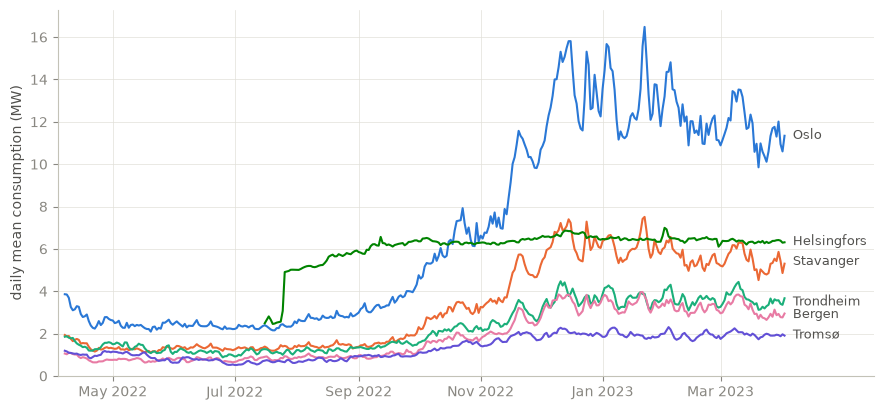

In [12]:
#Figure fig:consumption-level: daily mean consumption per location
daily = consumption.set_index("time").groupby("location")["consumption"].resample("D").mean().unstack(level=0)
fig, ax = plt.subplots(figsize=(9, 4.2))
for loc, color in COLORS.items():
    s = daily[loc].dropna()
    ax.plot(s.index, s, color=color, linewidth=1.5)
    ax.annotate(NAMES[loc], (s.index[-1], s.iloc[-7:].mean()), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#52514e")
ax.set_ylabel("daily mean consumption (MW)")
ax.set_ylim(bottom=0)
ax.margins(x=0.01)
ax.set_xlim(right=daily.index[-1] + pd.Timedelta(days=45))
ax.set_xticks(pd.date_range("2022-05-01", "2023-04-01", freq="2MS", tz="UTC"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout()
fig.savefig(FIGURES / "consumption_level.png", dpi=300)
plt.show()

## Consumption and temperature (2.3) ##

In [13]:
#Correlation of each weather variable with consumption, per location
#Raw weather columns, so the near-duplicates temperature_2m and wind_gusts_10m dropped from dataset.csv are included
weather_cols = merged_explorer.numeric_cols.drop("wind_direction_10m")
merged.groupby("location")[weather_cols].corr().xs("consumption", level=1).drop(columns="consumption").round(2)

,temperature,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,wind_gusts_10m
location,,,,,,,
bergen,-0.78,-0.79,0.02,-0.04,0.19,0.07,0.05
helsingfors,-0.60,-0.62,0.02,-0.04,0.12,0.11,0.06
oslo,-0.86,-0.86,-0.01,-0.07,0.20,-0.03,-0.12
stavanger,-0.78,-0.78,0.07,0.02,0.18,0.10,0.05
tromsø,-0.86,-0.86,-0.05,-0.12,0.18,0.04,0.08
trondheim,-0.84,-0.84,-0.07,-0.15,0.19,0.12,0.09


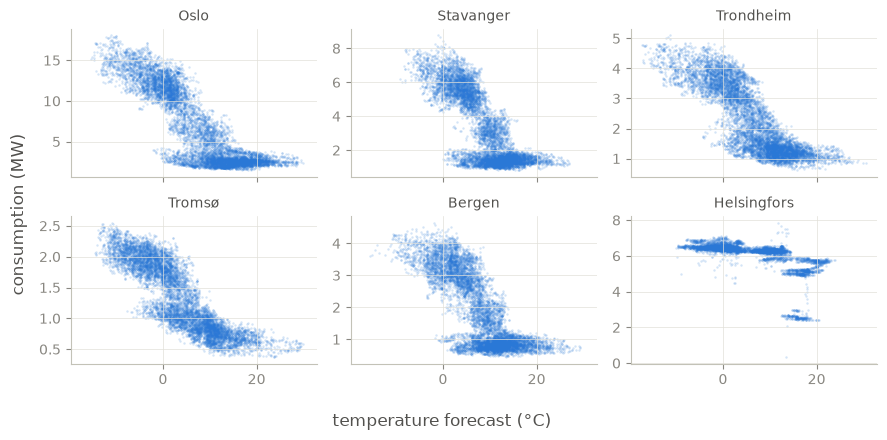

In [14]:
#Figure fig:temp-scatter: hourly consumption against the temperature forecast
fig, axes = plt.subplots(2, 3, figsize=(9, 4.4), sharex=True)
for ax, loc in zip(axes.flat, ORDER):
    g = consumption[consumption["location"] == loc].dropna(subset=["consumption"])
    ax.scatter(g["temperature"], g["consumption"], s=3, alpha=0.2, color=BLUE, linewidths=0)
    ax.set_title(NAMES[loc], fontsize=10, color="#52514e")
fig.supxlabel("temperature forecast (°C)", color="#52514e")
fig.supylabel("consumption (MW)", color="#52514e")
fig.tight_layout()
fig.savefig(FIGURES / "temperature_scatter.png", dpi=300)
plt.show()

## Daily and weekly patterns (2.3) ##

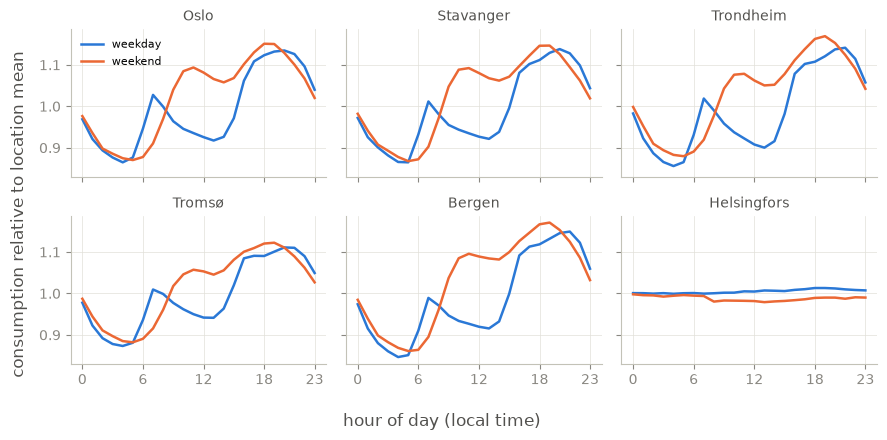

In [15]:
#Figure fig:daily-profiles: average daily profile in local time, weekdays against weekends
fig, axes = plt.subplots(2, 3, figsize=(9, 4.4), sharex=True, sharey=True)
for ax, loc in zip(axes.flat, ORDER):
    g = consumption[consumption["location"] == loc].dropna(subset=["consumption"]).copy()
    local = g["time"].dt.tz_convert(TIMEZONES.get(loc, "Europe/Oslo"))
    g["hour"], g["weekend"] = local.dt.hour, local.dt.dayofweek >= 5
    #Divide by the location's mean so the shape is comparable across portfolio sizes
    g["rel"] = g["consumption"] / g["consumption"].mean()
    prof = g.groupby(["weekend", "hour"])["rel"].mean().unstack(0)
    ax.plot(prof.index, prof[False], color=BLUE, lw=1.8, label="weekday")
    ax.plot(prof.index, prof[True], color=ORANGE, lw=1.8, label="weekend")
    ax.set_title(NAMES[loc], fontsize=10, color="#52514e")
    ax.set_xticks([0, 6, 12, 18, 23])
axes[0, 0].legend(frameon=False, fontsize=8)
fig.supxlabel("hour of day (local time)", color="#52514e")
fig.supylabel("consumption relative to location mean", color="#52514e")
fig.tight_layout()
fig.savefig(FIGURES / "daily_profiles.png", dpi=300)
plt.show()

## Findings ##
* **Missing values:** no NaNs, gaps or duplicate hours in either file. Helsingfors reports 0 MW for its first 32 hours (2022-07-14 21:00 to 2022-07-16 04:00 UTC); these are treated as missing.
* **Distributions:** the consumption level differs a lot between locations (Oslo largest, Tromsø smallest), so errors should also be compared relative to level (nMAE). Precipitation, rain and snowfall are zero most hours.
* **Level shifts:** at similar temperatures, Norwegian consumption in October 2022 is roughly 1.3 to 2 times the April 2022 level (Oslo 2.8 MW at 7.6 °C in April vs 6.1 MW at 8.1 °C in October). Helsingfors ramps up from about 2.6 to 6.3 MW during July to September 2022. This points to portfolio changes, which lagged consumption features capture but temperature alone does not.
* **Daily profiles:** on weekdays the Norwegian locations have a morning peak around 07:00 and a larger evening peak around 20:00; on weekends the morning peak comes later and is broader. Helsingfors is almost flat, with no weekend effect.
* **Correlation:** within a location, consumption and temperature have a correlation of about -0.80 (-0.60 in Helsingfors, -0.86 in Oslo and Tromsø). Wind and precipitation are only weakly related to consumption. The temperature effect is non-linear: almost flat above about 10 to 12 °C and steep below, which is consistent with a heating threshold.
* **Weather file:** `temperature_2m` correlates 0.99 with the delivered `temperature`. It is ERA5 reanalysis (observed weather), not a forecast, so it would not be available at 10:00 on the day before.